In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
from google.colab import files

uploaded = files.upload()

Saving samplesuperstore (1).csv to samplesuperstore (1).csv


In [4]:
import pandas as pd

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("Dataset uploaded successfully!")

df.head()

Dataset uploaded successfully!


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,1/3/2023,1/7/2023,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,1/5/2023,1/12/2023,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (10194, 21)

Column Names:
Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City',
       'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category',
       'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  object 
 6   Customer Name   10194 non-null  object 
 7   Segment         10194 non-null  object 
 8   Country/Region  10194 non-null  object 

In [6]:
df['Order Date'] = pd.to_datetime(
    df['Order Date'], errors='coerce'
)

df['Sales'] = pd.to_numeric(
    df['Sales'], errors='coerce'
)

df = df.dropna(subset=['Order Date', 'Sales'])

df = df.sort_values('Order Date')

print("Data cleaning completed!")

Data cleaning completed!


In [7]:
monthly_sales = (
    df.set_index('Order Date')['Sales']
    .resample('MS')
    .sum()
)

print(monthly_sales)

Order Date
2023-01-01     14518.0550
2023-02-01      4519.8920
2023-03-01     56933.9090
2023-04-01     28295.3450
2023-05-01     26319.7670
2023-06-01     34669.4796
2023-07-01     33946.3930
2023-08-01     28918.3385
2023-09-01     82670.4288
2023-10-01     32413.3390
2023-11-01     78826.9567
2023-12-01     72008.3085
2024-01-01     18461.9156
2024-02-01     11951.4110
2024-03-01     39978.6280
2024-04-01     34195.2085
2024-05-01     30246.9465
2024-06-01     24797.2920
2024-07-01     28765.3250
2024-08-01     37057.0042
2024-09-01     64627.0460
2024-10-01     31407.1335
2024-11-01     75972.5635
2024-12-01     75532.5572
2025-01-01     18830.3310
2025-02-01     22978.8150
2025-03-01     53031.0690
2025-04-01     38829.1590
2025-05-01     57042.8380
2025-06-01     40937.1480
2025-07-01     40300.4990
2025-08-01     31716.8143
2025-09-01     73521.6629
2025-10-01     59831.0010
2025-11-01     79411.9658
2025-12-01     97502.2770
2026-01-01     44259.2140
2026-02-01     20301.1334
2

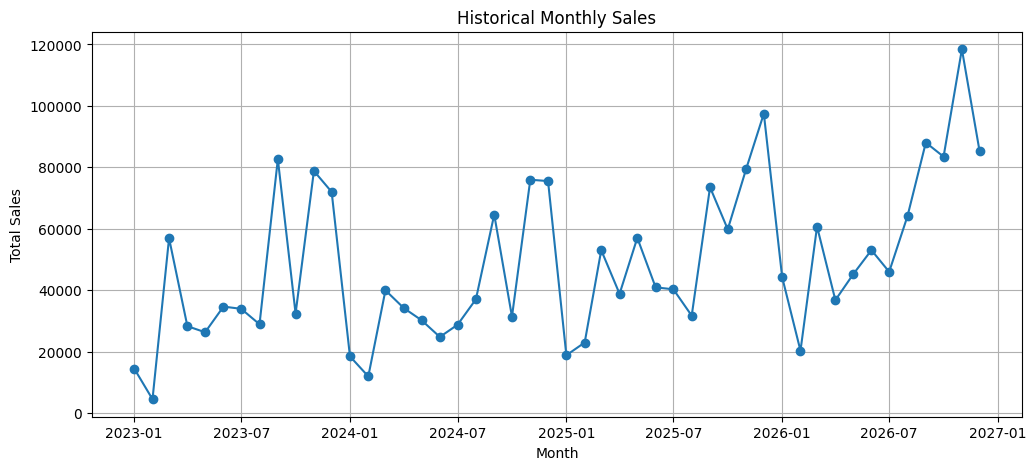

In [8]:
plt.figure(figsize=(12,5))

plt.plot(monthly_sales.index,
         monthly_sales.values,
         marker='o')

plt.title("Historical Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.grid(True)
plt.show()

In [9]:
data = monthly_sales.reset_index()

data.columns = ['Date', 'Sales']

data['Time'] = np.arange(len(data))

X = data[['Time']]
y = data['Sales']

In [10]:
split = int(len(data) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

In [11]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [12]:
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(mean_squared_error(
    y_test, predictions
))

nonzero = y_test != 0

mape = np.mean(
    np.abs(
        (y_test[nonzero] - predictions[nonzero])
        / y_test[nonzero]
    )
) * 100

print("MAE:", mae)
print("RMSE:", rmse)
print("MAPE:", mape, "%")

MAE: 18858.470063211513
RMSE: 23943.345345302114
MAPE: 26.841897916501487 %


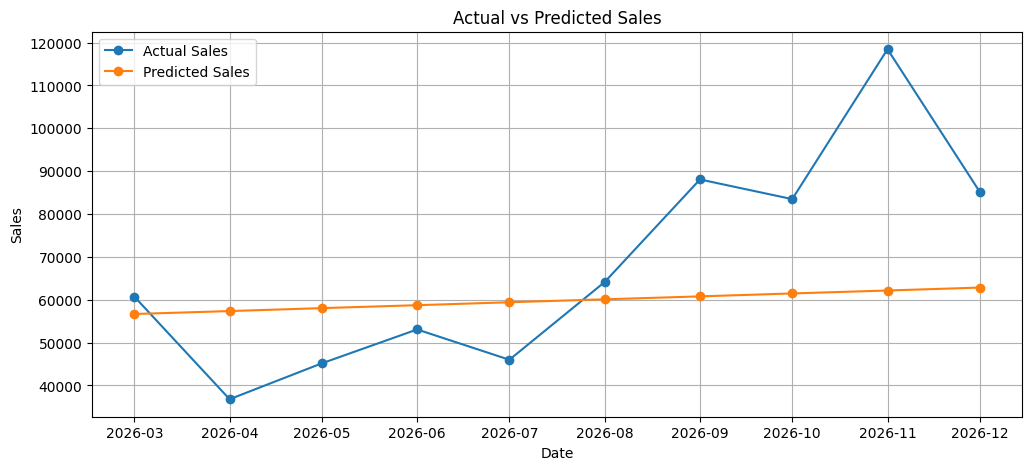

In [13]:
plt.figure(figsize=(12,5))

plt.plot(data['Date'].iloc[split:],
         y_test,
         label='Actual Sales',
         marker='o')

plt.plot(data['Date'].iloc[split:],
         predictions,
         label='Predicted Sales',
         marker='o')

plt.title("Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()
plt.grid(True)
plt.show()

In [14]:
future_periods = 6

future_time = np.arange(
    len(data),
    len(data) + future_periods
)

future_X = pd.DataFrame({
    'Time': future_time
})

future_predictions = model.predict(future_X)

future_dates = pd.date_range(
    start=data['Date'].max() + pd.offsets.MonthBegin(1),
    periods=future_periods,
    freq='MS'
)

forecast = pd.DataFrame({
    'Month': future_dates,
    'Predicted Sales': future_predictions
})

print(forecast)

       Month  Predicted Sales
0 2027-01-01     63518.039975
1 2027-02-01     64203.283819
2 2027-03-01     64888.527662
3 2027-04-01     65573.771506
4 2027-05-01     66259.015349
5 2027-06-01     66944.259193


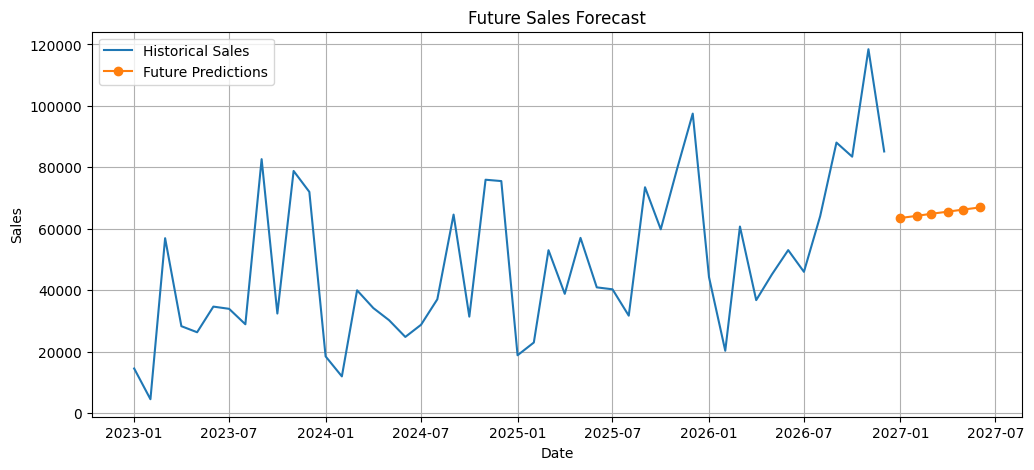

In [15]:
plt.figure(figsize=(12,5))

plt.plot(data['Date'],
         data['Sales'],
         label='Historical Sales')

plt.plot(future_dates,
         future_predictions,
         label='Future Predictions',
         marker='o')

plt.title("Future Sales Forecast")

plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()
plt.grid(True)
plt.show()